# BNC2 - Analyses statistiques R1 à R4

Notebook des analyses du nouveau récit :

| Bloc | Question |
|---|---|
| **R1** | Combien vaut le service rendu par les forêts (GCW) ? |
| **R2** | Que change l'ajout du bleu (NCW), et comment se place chaque pays face à ses émissions ? |
| **R3** | Quelle part de ce service est détruite par la déforestation ? |
| **R4** | Combien coûterait de compenser cette perte, et qui la supporte ? |

Conventions :

- les intervalles monétaires propagent les 20 000 tirages du GSCC ; taux moyens par biome et surfaces forestières sont fixes dans l’estimation principale ;
- normalisation principale = **ratio au PIB** ; les indicateurs par habitant sont en **annexe**  ;
- le service forestier correspond aux **ajouts bruts annuels à la biomasse vivante aérienne et souterraine** estimés par Gibbs/GFW ; la déforestation est traitée séparément comme perte de capacité annuelle ;
- l’écart-type spatial Gibbs/GFW décrit la dispersion entre pixels et n’est pas une incertitude statistique du taux moyen.

## 0. Chargement et utilitaires

In [1]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA, OUT = ROOT / "data", ROOT / "output"
FIG = OUT / "figures" / "notebook"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.25})

CARBON_TO_CO2 = 44.0 / 12.0
GROUP_ORDER = ["Developed economies", "Developing economies", "LDCs", "SIDS"]
GROUP_COLORS = dict(zip(GROUP_ORDER, ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]))
print("racine du dépôt :", ROOT)

racine du dépôt : <paper-project>\repo


In [2]:
gcw = pd.read_csv(OUT / "country_level_gcw.csv")
ncw = pd.read_csv(OUT / "country_level_ncw.csv")
terr = pd.read_csv(DATA / "summary" / "territories.csv")
rates = pd.read_csv(DATA / "summary" / "gfw_gibbs_biome_rates.csv").set_index("biome")
area_biome = pd.read_csv(DATA / "summary" / "forest_area_by_biome.csv")

gcw_npz = np.load(OUT / "draws" / "gcw_draws.npz", allow_pickle=True)
ncw_npz = np.load(OUT / "draws" / "ncw_draws.npz", allow_pickle=True)

GSCC = gcw_npz["gscc"].astype("float64")             # (20000,) US$2015 / tCO2
UNITS = ncw_npz["iso3"].astype(str)                   # 266 unités comptables 
D_GCW = ncw_npz["gcw_usd2015_yr"].astype("float64")   # (266, 20000)
D_BCW = ncw_npz["bcw_usd2015_yr"].astype("float64")
D_NCW = ncw_npz["ncw_usd2015_yr"].astype("float64")
N_DRAWS = GSCC.size

# RÈGLE NaN  : une valeur absente reste NaN, jamais 0.
# 0 signifie « mesuré et nul », NaN signifie « on ne sait pas ». Les totaux sont donc des
# `nansum` explicites, accompagnés du nombre d'unités qui y contribuent.
HAS_GCW = ~np.isnan(D_GCW[:, 0])
HAS_BCW = ~np.isnan(D_BCW[:, 0])
HAS_NCW = ~np.isnan(D_NCW[:, 0])
for label, mask in (("GCW", HAS_GCW), ("BCW", HAS_BCW), ("NCW", HAS_NCW)):
    print(f"{label} : {int(mask.sum())} unités renseignées, {int((~mask).sum())} sans donnée (NaN, pas 0)")

print(f"{len(UNITS)} unités, {N_DRAWS} tirages ; GSCC moyen = {GSCC.mean():.1f} US$2015/tCO2")

GCW : 236 unités renseignées, 31 sans donnée (NaN, pas 0)
BCW : 181 unités renseignées, 86 sans donnée (NaN, pas 0)
NCW : 242 unités renseignées, 25 sans donnée (NaN, pas 0)
267 unités, 20000 tirages ; GSCC moyen = 559.6 US$2015/tCO2


In [3]:
def summarise(draws, label="valeur"):
    """Résume une distribution de tirages (moyenne, médiane, sd, p5, p95)."""
    d = np.asarray(draws, dtype="float64")
    return pd.Series({"mean": d.mean(), "p50": np.median(d), "sd": d.std(ddof=1),
                      "p05": np.percentile(d, 5), "p95": np.percentile(d, 95)}, name=label)


def summarise_rows(draws, index, prefix=""):
    """Résume ligne par ligne une matrice (unités x tirages)."""
    d = np.asarray(draws, dtype="float64")
    return pd.DataFrame({f"{prefix}mean": d.mean(axis=1),
                         f"{prefix}p50": np.median(d, axis=1),
                         f"{prefix}sd": d.std(axis=1, ddof=1),
                         f"{prefix}p05": np.percentile(d, 5, axis=1),
                         f"{prefix}p95": np.percentile(d, 95, axis=1)}, index=index)


def usd(x, unit="T"):
    """Formate un montant en US$ (T = trillions, B = milliards, M = millions)."""
    div = {"T": 1e12, "B": 1e9, "M": 1e6}[unit]
    return f"{x / div:,.2f} {unit}$"


def gini(x):
    x = np.sort(np.asarray(x, dtype="float64"))
    x = x[~np.isnan(x)]
    if x.size == 0 or x.sum() == 0:
        return np.nan
    n = x.size
    return float((2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum()))


def lorenz_points(x):
    x = np.sort(np.asarray(x, dtype="float64"))
    x = x[~np.isnan(x)]
    return np.linspace(0, 1, x.size + 1), np.concatenate([[0], np.cumsum(x) / x.sum()])


def pairwise_mannwhitney(values_by_group):
    """Comparaisons deux à deux, alternative non paramétrique au post-hoc de Dunn."""
    names = list(values_by_group)
    rows = []
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            u, p = stats.mannwhitneyu(values_by_group[a], values_by_group[b], alternative="two-sided")
            rows.append({"groupe A": a, "groupe B": b, "U": u, "p brut": p})
    out = pd.DataFrame(rows).sort_values("p brut").reset_index(drop=True)
    m = len(out)
    adj = np.maximum.accumulate((m - np.arange(m)) * out["p brut"].to_numpy())
    out["p ajusté (Holm)"] = np.clip(adj, 0, 1)
    return out

### Table de travail

Une ligne par unité comptable , avec groupe, PIB, population, émissions et dette.
Les émissions et la dette viennent de la table BCW publiée : comme la population et le PIB, elles
**ne sont jamais sommées** entre les parties d'un même pays , on prend la valeur de la ligne principale.

In [4]:
bcw_raw = pd.read_csv(DATA / "raw" / "bcw" / "output" / "country_level_bcw.csv")
bcw_raw["ISO"] = bcw_raw["ISO"].astype(str)

code_to_unit = {}
for _, r in terr.dropna(subset=["bcw_codes"]).iterrows():
    for code in str(r["bcw_codes"]).split(";"):
        code_to_unit[code] = r["iso3"]

bcw_raw["unit"] = bcw_raw["ISO"].map(code_to_unit)
socio = (bcw_raw.dropna(subset=["unit"]).sort_values("CO2_emissions_2023", ascending=False)
         .groupby("unit")[["CO2_emissions_2023", "Debt (2015 US$)"]].first()
         .rename(columns={"CO2_emissions_2023": "co2_emissions_tco2_2023",
                          "Debt (2015 US$)": "debt_usd2015"}))

base = (ncw.drop(columns=[c for c in ("continent", "groups", "population", "gdp") if c in ncw.columns])
        .merge(terr[["iso3", "continent", "groups", "population", "gdp"]], on="iso3", how="left")
        .merge(socio, left_on="iso3", right_index=True, how="left"))
base["debt_share_of_gdp"] = 100 * base["debt_usd2015"] / base["gdp"]
print(base.shape, "| unités sans émissions :", int(base["co2_emissions_tco2_2023"].isna().sum()))
base.head(3)

(267, 34) | unités sans émissions : 56


,iso3,name,bcw_codes,fra_region,ncw_usd2015_yr_mean,ncw_usd2015_yr_sd,ncw_usd2015_yr_p05,ncw_usd2015_yr_p50,ncw_usd2015_yr_p95,ncw_spatial_sd_low_usd2015_yr_mean,ncw_spatial_sd_high_usd2015_yr_mean,gcw_usd2015_yr_mean,gcw_usd2015_yr_p05,gcw_usd2015_yr_p95,bcw_usd2015_yr_mean,bcw_usd2015_yr_p05,bcw_usd2015_yr_p95,bcw_published_usd2015_yr_mean,bcw_mangrove_gapfill_usd2015_yr_mean,bcw_gmw_mangroves_usd2015_yr_mean,ncw_alt_mangroves_usd2015_yr_mean,has_gcw,has_bcw,bcw_mangrove_gapfilled,ncw_per_capita_usd2015,ncw_share_of_gdp,forest_share_of_ncw,continent,groups,population,gdp,co2_emissions_tco2_2023,debt_usd2015,debt_share_of_gdp
0,RUS,Russian Federation,RUS,Europe,1.310999e+12,6.292804e+11,5.119468e+11,1.187090e+12,2.380001e+12,7.608508e+11,1.861147e+12,1.212942e+12,4.737144e+11,2.202177e+12,9.805708e+10,3.829763e+10,1.780425e+11,9.805708e+10,NaN,0.000000e+00,1.310999e+12,True,True,False,9013.989228,0.859942,0.925204,Europe,Developed economies,145440500.0,1.524520e+12,1.815925e+09,NaN,NaN
1,USA,United States of America,US-AK;US-HI;USA,North and Central America,9.877102e+11,4.740966e+11,3.857794e+11,8.945930e+11,1.792479e+12,4.312581e+11,1.544162e+12,8.165317e+11,3.188964e+11,1.482468e+12,1.711785e+11,6.695406e+10,3.105221e+11,1.710958e+11,NaN,9.552041e+08,9.867550e+11,True,True,False,2875.619718,0.045357,0.826692,Americas,Developed economies,343477335.0,2.177628e+13,4.911391e+09,NaN,NaN
2,BRA,Brazil,BR-ES;BRA,South America,9.726587e+11,4.668765e+11,3.801569e+11,8.816078e+11,1.764889e+12,3.858296e+10,1.906734e+12,9.424669e+11,3.680804e+11,1.711111e+12,3.019182e+10,1.160817e+10,5.829526e+10,3.042104e+10,NaN,4.073361e+09,9.685853e+11,True,True,False,4606.684306,0.497587,0.968959,Americas,Developing economies,211140729.0,1.954752e+12,4.864701e+08,4.583722e+11,23.449121


**Année de référence socio-économique : 2023**, convention reprise de BCW (méthodes de Hilmi et al. 2026) :

| Variable | Source | Année |
|---|---|---|
| Émissions de CO₂ | Global Carbon Budget 2024 via Our World in Data ; **fossile et industrie, hors usage des terres** | 2023 |
| Dette extérieure totale | Banque mondiale, *External Debt Stocks, Total (DOD)* | 2023 |
| Population | UN WPP 2024 | 2023 |
| PIB | 2023 ou l'année antérieure la plus proche | 2023 |

Deux conséquences :

1. les émissions **excluent le changement d'usage des terres**, donc le bilan net de R2 ne compte pas deux fois la déforestation traitée en R3 ;
2. le flux forestier porte sur 2010-2019  et les surfaces sont celles de FRA 2025 : le décalage temporel existe déjà et il est documenté comme limite. Aligner les émissions sur une année plus récente que 2023 casserait la cohérence avec la population, le PIB et la dette, sans supprimer ce décalage.

> **TODO** : reste à obtenir le seuil de tension de dette utilisé dans la Fig. 5c de BCW.

## R1 - Le service rendu par les forêts (GCW)

Question : *quelle est la valeur annuelle des ajouts bruts de carbone à la biomasse vivante des forêts existantes ?*
Méthode : surface FRA 2025 × parts des quatre biomes FAO GEZ × taux moyens de gross removals Gibbs/GFW (biomasse vivante aérienne et souterraine) × 44/12 × GSCC. Les taux sont fixes dans l’estimation principale ; les tirages monétaires reflètent l’incertitude du GSCC.

### R1.1 Total mondial, par biome et par groupe

In [5]:
world = pd.concat([summarise(np.nansum(D_GCW, axis=0), "GCW"),
                   summarise(np.nansum(D_BCW, axis=0), "BCW"),
                   summarise(np.nansum(D_NCW, axis=0), "NCW")], axis=1).T
display(world.map(usd))

uptake_world = np.nansum(D_GCW, axis=0) / GSCC   # tirage par tirage, unités renseignées seulement
print("ajouts bruts annuels à la biomasse forestière vivante (Gibbs/GFW) :",
      f"{uptake_world.mean() / 1e9:.2f} GtCO2/an",
      f"({uptake_world.mean() / CARBON_TO_CO2 / 1e9:.2f} GtC/an)")

,mean,p50,sd,p05,p95
GCW,8.24 T$,7.47 T$,3.96 T$,3.22 T$,14.97 T$
BCW,2.33 T$,2.11 T$,1.13 T$,0.91 T$,4.30 T$
NCW,10.57 T$,9.59 T$,5.08 T$,4.16 T$,19.17 T$


ajouts bruts annuels à la biomasse forestière vivante (Gibbs/GFW) : 14.73 GtCO2/an (4.02 GtC/an)


In [6]:
# Par biome : surfaces harmonisées x taux moyens Gibbs/GFW, overlap FRA retiré seulement s'il est documenté comme Forest
ab = area_biome.query("variant == 'documented_overlap_removed'")
biome = (ab.groupby("biome")["area_ha"].sum().to_frame("area_ha")
         .join(rates[["rate_tc_ha_yr_mean", "rate_tc_ha_yr_spatial_sd"]]))
biome["uptake_gtco2_yr"] = biome["area_ha"] * biome["rate_tc_ha_yr_mean"] * CARBON_TO_CO2 / 1e9
biome["gcw_bn_usd_yr"] = biome["uptake_gtco2_yr"] * 1e9 * GSCC.mean() / 1e9
biome["share_%"] = 100 * biome["uptake_gtco2_yr"] / biome["uptake_gtco2_yr"].sum()
display(biome.round(2))

,area_ha,rate_tc_ha_yr_mean,rate_tc_ha_yr_spatial_sd,uptake_gtco2_yr,gcw_bn_usd_yr,share_%
biome,,,,,,
boreal,1.135233e+09,0.62,0.26,2.58,1440.94,17.48
subtropical,4.647601e+08,1.37,1.32,2.34,1307.11,15.85
temperate,6.163773e+08,1.43,0.80,3.23,1808.55,21.94
tropical,1.923578e+09,0.93,0.93,6.59,3687.82,44.73


In [7]:
groups = base.set_index("iso3")["groups"].reindex(UNITS)
rows = {}
for g in GROUP_ORDER:
    mask = (groups == g).to_numpy()
    tot = np.nansum(D_GCW[mask], axis=0)
    rows[g] = {"n": int(mask.sum()), **summarise(tot).to_dict(),
               "avec GCW": int((mask & HAS_GCW).sum()),
               "part du monde (%)": 100 * tot.mean() / np.nansum(D_GCW, axis=0).mean()}
tab_group = pd.DataFrame(rows).T
display(tab_group.assign(**{c: tab_group[c].map(usd) for c in ["mean", "p50", "sd", "p05", "p95"]}))

,n,mean,p50,sd,p05,p95,avec GCW,part du monde (%)
Developed economies,68.0,3.61 T$,3.27 T$,1.73 T$,1.41 T$,6.55 T$,60.0,43.745237
Developing economies,88.0,3.42 T$,3.10 T$,1.64 T$,1.34 T$,6.21 T$,80.0,41.464442
LDCs,37.0,1.05 T$,0.96 T$,0.51 T$,0.41 T$,1.91 T$,37.0,12.791969
SIDS,57.0,0.16 T$,0.15 T$,0.08 T$,0.06 T$,0.30 T$,57.0,1.996557


### R1.2 Poids économique : ratio GCW/PIB (normalisation principale)

In [8]:
r1 = base.dropna(subset=["gcw_usd2015_yr_mean"]).copy()
r1["gcw_share_of_gdp"] = 100 * r1["gcw_usd2015_yr_mean"] / r1["gdp"]
print("GCW mondial / PIB mondial :",
      f"{100 * r1['gcw_usd2015_yr_mean'].sum() / r1['gdp'].sum():.1f} %")
display(r1.nlargest(15, "gcw_share_of_gdp")[["name", "groups", "gcw_usd2015_yr_mean", "gcw_share_of_gdp"]]
        .assign(gcw_usd2015_yr_mean=lambda d: d["gcw_usd2015_yr_mean"].map(lambda v: usd(v, "B"))).round(1))
display(r1.groupby("groups")["gcw_share_of_gdp"].describe()[["count", "50%", "mean", "max"]].round(1))

GCW mondial / PIB mondial : 9.0 %


,name,groups,gcw_usd2015_yr_mean,gcw_share_of_gdp
23,Central African Republic,LDCs,86.45 B$,4212.4
58,Suriname,SIDS,28.13 B$,624.4
7,Democratic Republic of the Congo,LDCs,266.85 B$,469.5
38,Congo,Developing economies,41.90 B$,404.1
81,Liberia,LDCs,12.13 B$,337.9
24,Zambia,LDCs,86.03 B$,310.4
79,Solomon Islands,SIDS,4.82 B$,310.1
27,Mozambique,LDCs,61.82 B$,302.5
30,Gabon,Developing economies,45.16 B$,278.5
17,Bolivia (Plurinational State of),Developing economies,104.24 B$,265.5


,count,50%,mean,max
groups,,,,
Developed economies,53.0,4.0,10.8,79.6
Developing economies,67.0,8.7,39.2,404.1
LDCs,34.0,54.6,212.0,4212.4
SIDS,49.0,4.4,47.6,624.4


### R1.3 Concentration : Lorenz, Gini, part des dix premiers

Gini du GCW entre pays : 0.866
Part des 10 premiers pays : 64.1 %


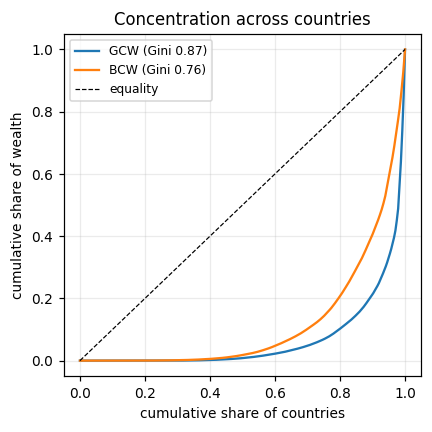

,name,groups,gcw_usd2015_yr_mean,gcw_share_of_gdp
0,Russian Federation,Developed economies,"1,212.94 B$",79.6
2,Brazil,Developing economies,942.47 B$,48.2
1,United States of America,Developed economies,816.53 B$,3.7
3,Canada,Developed economies,629.36 B$,35.4
4,"China (incl. Taiwan, Hong Kong SAR and Macao SAR)",Developing economies,616.03 B$,3.6
5,Australia,Developed economies,315.99 B$,19.3
7,Democratic Republic of the Congo,LDCs,266.85 B$,469.5
6,Indonesia,Developing economies,183.99 B$,15.6
8,Mexico,Developing economies,150.85 B$,11.4
10,India,Developing economies,146.07 B$,4.6


In [9]:
vals = r1["gcw_usd2015_yr_mean"].to_numpy()
top10 = r1.nlargest(10, "gcw_usd2015_yr_mean")
print(f"Gini du GCW entre pays : {gini(vals):.3f}")
print(f"Part des 10 premiers pays : {100 * top10['gcw_usd2015_yr_mean'].sum() / vals.sum():.1f} %")

fig, ax = plt.subplots(figsize=(4, 4))
x, y = lorenz_points(vals)
ax.plot(x, y, label=f"GCW (Gini {gini(vals):.2f})")
bcw_vals = base["bcw_usd2015_yr_mean"].dropna().to_numpy()
xb, yb = lorenz_points(bcw_vals)
ax.plot(xb, yb, label=f"BCW (Gini {gini(bcw_vals):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="equality")
ax.set_xlabel("cumulative share of countries"); ax.set_ylabel("cumulative share of wealth")
ax.set_title("Concentration across countries"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "R1_lorenz.png"); plt.show()

display(top10[["name", "groups", "gcw_usd2015_yr_mean", "gcw_share_of_gdp"]]
        .assign(gcw_usd2015_yr_mean=lambda d: d["gcw_usd2015_yr_mean"].map(lambda v: usd(v, "B"))).round(1))

### R1.4 Dotation écologique contre taille économique (commentaire des coauteurs n°16)

Spearman GCW ~ PIB : rho = 0.61 (p = 2.2e-21, n = 200)


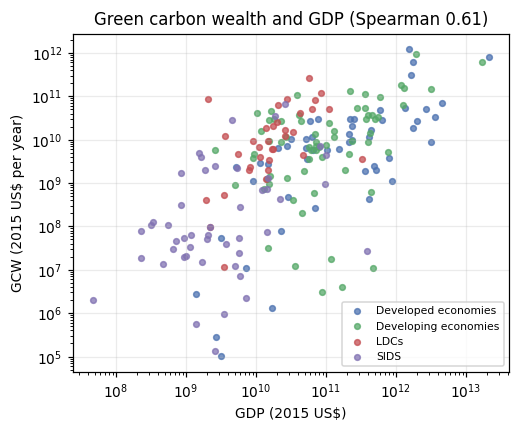

In [10]:
sub = r1.dropna(subset=["gdp"]).query("gdp > 0 and gcw_usd2015_yr_mean > 0")
rho, p = stats.spearmanr(sub["gcw_usd2015_yr_mean"], sub["gdp"])
print(f"Spearman GCW ~ PIB : rho = {rho:.2f} (p = {p:.1e}, n = {len(sub)})")

fig, ax = plt.subplots(figsize=(4.8, 4))
for g, d in sub.groupby("groups"):
    ax.scatter(d["gdp"], d["gcw_usd2015_yr_mean"], s=14, alpha=0.75, label=g,
               color=GROUP_COLORS.get(g, "grey"))
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("GDP (2015 US$)"); ax.set_ylabel("GCW (2015 US$ per year)")
ax.set_title(f"Green carbon wealth and GDP (Spearman {rho:.2f})"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "R1_gcw_vs_gdp.png"); plt.show()

### R1.5 Les groupes diffèrent-ils ? (Kruskal-Wallis puis comparaisons deux à deux)

In [11]:
vals_by_group = {g: r1.loc[r1["groups"] == g, "gcw_share_of_gdp"].dropna().to_numpy() for g in GROUP_ORDER}
vals_by_group = {g: v for g, v in vals_by_group.items() if v.size > 2}
h, p = stats.kruskal(*vals_by_group.values())
print(f"Kruskal-Wallis sur GCW/PIB : H = {h:.1f}, p = {p:.2e}")
display(pairwise_mannwhitney(vals_by_group).round(4))

Kruskal-Wallis sur GCW/PIB : H = 38.5, p = 2.20e-08


,groupe A,groupe B,U,p brut,p ajusté (Holm)
0,Developed economies,LDCs,222.0,0.0000,0.0000
1,LDCs,SIDS,1311.0,0.0000,0.0000
2,Developing economies,LDCs,542.0,0.0000,0.0001
3,Developed economies,Developing economies,1281.0,0.0090,0.0271
4,Developing economies,SIDS,1996.0,0.0479,0.0957
5,Developed economies,SIDS,1202.0,0.5202,0.5202


### R1.6 Stabilité des rangs sous incertitude

Probabilité, sur les 20 000 tirages, qu'un pays figure dans les dix premiers.
Les taux de biome étant partagés par tous les pays , les rangs ne bougent qu'entre pays de biomes différents.

In [12]:
order = np.argsort(-np.nan_to_num(D_GCW, nan=-np.inf), axis=0)   # les NaN ne peuvent pas entrer au classement
counts = np.zeros(len(UNITS))
np.add.at(counts, order[:10].ravel(), 1)
prob = pd.Series(counts / N_DRAWS, index=UNITS, name="P(top 10)")
names = base.set_index("iso3")["name"]
display(prob[prob > 0].sort_values(ascending=False).to_frame().join(names).head(15).round(3))

,P(top 10),name
AUS,1.0,Australia
BRA,1.0,Brazil
CAN,1.0,Canada
CHN,1.0,"China (incl. Taiwan, Hong Kong SAR and Macao SAR)"
COD,1.0,Democratic Republic of the Congo
IDN,1.0,Indonesia
IND,1.0,India
MEX,1.0,Mexico
RUS,1.0,Russian Federation
USA,1.0,United States of America


> **Pas de régression du GCW sur la surface ou les biomes** : le GCW est construit comme surface × taux,
> une telle régression serait tautologique .

## R2 - De GCW à NCW

Deux questions : de quoi est faite la richesse carbone de chaque pays, verte ou bleue,
et où se situe chaque pays face à ses propres émissions.

### R2.1 Composition verte / bleue

composition calculable pour 175 unités sur 242


profil,mixte,à dominante bleue,à dominante verte
groups,,,
Developed economies,6,9,22
Developing economies,14,16,30
LDCs,6,3,12
SIDS,12,37,8


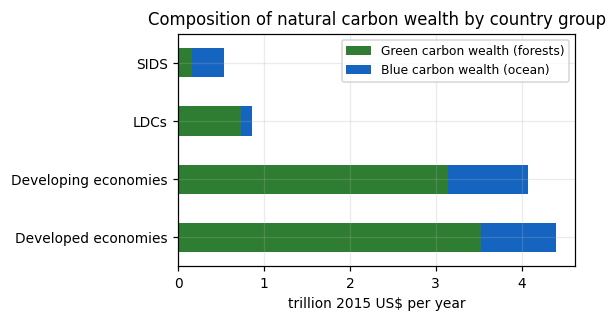

In [13]:
comp = base.dropna(subset=["ncw_usd2015_yr_mean"]).copy()
# composition calculée uniquement là où les deux composantes sont connues 
comp = comp[comp["has_gcw"] & comp["has_bcw"]].copy()
print(f"composition calculable pour {len(comp)} unités sur {int(base['ncw_usd2015_yr_mean'].notna().sum())}")
comp["forest_share"] = 100 * comp["gcw_usd2015_yr_mean"] / comp["ncw_usd2015_yr_mean"]
THRESHOLD = 66.7   # TODO : seuil de classification à valider
comp["profil"] = np.select([comp["forest_share"] >= THRESHOLD, comp["forest_share"] <= 100 - THRESHOLD],
                           ["à dominante verte", "à dominante bleue"], default="mixte")
display(pd.crosstab(comp["groups"], comp["profil"]))

fig, ax = plt.subplots(figsize=(5.4, 3))
agg = comp.groupby("groups")[["gcw_usd2015_yr_mean", "bcw_usd2015_yr_mean"]].sum().reindex(GROUP_ORDER) / 1e12
agg.plot(kind="barh", stacked=True, ax=ax, color=["#2E7D32", "#1565C0"])
ax.set_xlabel("trillion 2015 US$ per year"); ax.set_ylabel("")
ax.legend(["Green carbon wealth (forests)", "Blue carbon wealth (ocean)"], fontsize=8)
ax.set_title("Composition of natural carbon wealth by country group")
fig.tight_layout(); fig.savefig(FIG / "R2_composition.png"); plt.show()

### R2.2 Solde comptable après soustraction des émissions

Reprise de la Fig. 5a de BCW, étendue au vert . Le solde affiché compare les flux retenus dans les comptes forêt et océan aux émissions nationales de CO₂. Pour la forêt, le terme vert est l'ajout brut annuel à la biomasse vivante estimé par Gibbs/GFW. Ce solde comptable n'est pas un bilan net du carbone de l'écosystème forestier.

unités avec émissions renseignées : 211 ; bilan calculable pour 210
solde positif - compte forestier : 38 % | compte forêt + océan : 54 %


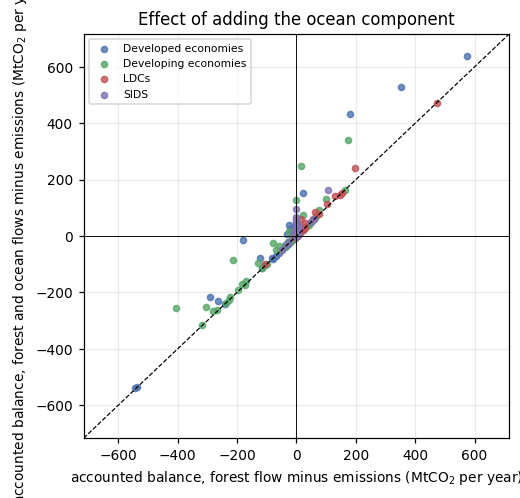

In [14]:
emis = base.set_index("iso3")["co2_emissions_tco2_2023"].reindex(UNITS).to_numpy()
seq_gcw = D_GCW / GSCC          # tCO2/an, tirage par tirage
seq_ncw = D_NCW / GSCC
bal_gcw = seq_gcw - emis[:, None]
bal_ncw = seq_ncw - emis[:, None]
ok = ~np.isnan(emis)

balance = pd.DataFrame({"iso3": UNITS,
                        "bal_gcw": bal_gcw.mean(axis=1), "bal_ncw": bal_ncw.mean(axis=1),
                        "p_sink_gcw": (bal_gcw > 0).mean(axis=1),
                        "p_sink_ncw": (bal_ncw > 0).mean(axis=1)})
balance = (balance[ok].dropna(subset=["bal_gcw", "bal_ncw"])   # NaN = composante inconnue 
           .merge(base[["iso3", "name", "groups", "debt_share_of_gdp", "gdp"]], on="iso3"))

print(f"unités avec émissions renseignées : {int(ok.sum())} ; bilan calculable pour {len(balance)}")
print(f"solde positif - compte forestier : {100 * (balance['bal_gcw'] > 0).mean():.0f} %"
      f" | compte forêt + océan : {100 * (balance['bal_ncw'] > 0).mean():.0f} %")

fig, ax = plt.subplots(figsize=(4.8, 4.6))
for g, d in balance.groupby("groups"):
    ax.scatter(d["bal_gcw"] / 1e6, d["bal_ncw"] / 1e6, s=16, alpha=0.8,
               color=GROUP_COLORS.get(g, "grey"), label=g)
lim = np.nanpercentile(np.abs(balance[["bal_gcw", "bal_ncw"]].to_numpy()) / 1e6, 97)
ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8)
ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("accounted balance, forest flow minus emissions (MtCO$_2$ per year)")
ax.set_ylabel("accounted balance, forest and ocean flows minus emissions (MtCO$_2$ per year)")
ax.set_title("Effect of adding the ocean component"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "R2_balance_1to1.png"); plt.show()

### R2.3 Solde comptable et tension de dette (Fig. 5c de BCW)

Axe vertical : solde comptable des flux retenus moins émissions ; le seuil 0 sépare soldes positifs et négatifs, sans qualifier le bilan carbone net des écosystèmes.
Axe horizontal : dette rapportée au PIB, seuil de tension `DEBT_THRESHOLD`.

quadrant,solde comptable négatif / dette faible,solde comptable négatif / dette élevée,solde comptable positif / dette faible,solde comptable positif / dette élevée
groups,,,,
Developed economies,2,4,1,1
Developing economies,23,5,19,5
LDCs,2,2,24,6
SIDS,3,1,14,5


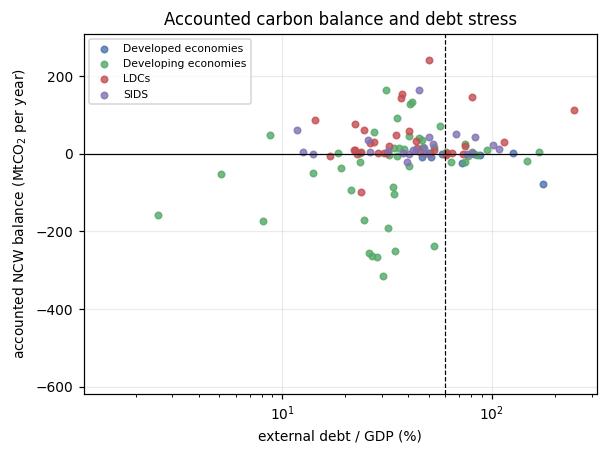

In [15]:
DEBT_THRESHOLD = 60.0   # TODO : reprendre le seuil exact de la Fig. 5c de BCW

q = balance.dropna(subset=["debt_share_of_gdp"]).copy()
q["position carbone"] = np.where(q["bal_ncw"] > 0, "solde comptable positif", "solde comptable négatif")
q["position dette"] = np.where(q["debt_share_of_gdp"] > DEBT_THRESHOLD, "dette élevée", "dette faible")
q["quadrant"] = q["position carbone"] + " / " + q["position dette"]
display(pd.crosstab(q["groups"], q["quadrant"]))

fig, ax = plt.subplots(figsize=(5.6, 4.2))
for g, d in q.groupby("groups"):
    ax.scatter(d["debt_share_of_gdp"], d["bal_ncw"] / 1e6, s=18, alpha=0.8,
               color=GROUP_COLORS.get(g, "grey"), label=g)
for _, row in q.reindex(q["bal_ncw"].abs().nlargest(6).index).iterrows():
    ax.annotate(row["iso3"], (row["debt_share_of_gdp"], row["bal_ncw"] / 1e6), fontsize=7)
ax.axhline(0, color="k", lw=0.8); ax.axvline(DEBT_THRESHOLD, color="k", ls="--", lw=0.8)
ax.set_xscale("log")
ax.set_ylim(np.nanpercentile(q["bal_ncw"] / 1e6, 2), np.nanpercentile(q["bal_ncw"] / 1e6, 98))
ax.set_xlabel("external debt / GDP (%)"); ax.set_ylabel("accounted NCW balance (MtCO$_2$ per year)")
ax.set_title("Accounted carbon balance and debt stress"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "R2_quadrants.png"); plt.show()

### R2.4 Figure en barres : émissions et flux comptabilisés

La figure compare le total des flux comptabilisés (vert et bleu) aux émissions nationales. Le terme vert désigne les ajouts bruts annuels à la biomasse forestière vivante, et non le bilan net de lécosystème.
La part déjà détruite par la déforestation est ajoutée en R3, pour que la figure dise quelque chose
que la Fig. 5 de BCW ne disait pas.

**Lecture de la figure** (textes en anglais, comme toutes les figures du papier) :

- **moitié gauche** : les dix plus gros émetteurs, classés du plus gros au plus petit ;
- **moitié droite** : les dix plus grands flux comptabilisés parmi les autres pays, classés en ordre croissant,
  donc le plus grand est tout à droite. La figure dessine ainsi un « V » : émissions à gauche, flux comptabilisés à droite ;
- **largeur des barres** : `WIDTH_METRIC` pilote cette dimension.
  - `"equal"` (retenu ici) : largeurs égales, hauteurs = totaux nationaux en MtCO₂/an ;
  - `"population"` : largeur proportionnelle à la population, hauteurs **par habitant**, donc l'**aire** vaut
    le total national (diagramme de Marimekko). Testé : la Chine, l'Inde et les États-Unis écrasent les autres
    barres et les étiquettes deviennent illisibles, cette version est donc reléguée en annexe ;
  - `"gdp"` : largeur proportionnelle au PIB, hauteurs = intensité carbone ;
- **couleurs** : le vert représente les ajouts bruts à la biomasse forestière vivante ; le flux bleu comptabilisé est distingué par des hachures.

**Unités** : tout est en tonnes de CO₂ par an. Les ajouts bruts forestiers viennent directement de la colonne
physique `uptake_tco2_yr_mean` du pipeline. Pour le BCW, aucune colonne physique n'est publiée : on divise les
tirages de valeur par les tirages de GSCC, ce qui reconstitue les tonnes impliquées par cette valorisation. Les
deux termes sont juxtaposés pour l'exercice comptable, sans prétendre qu'ils mesurent le même processus biophysique.

gauche : CHN, USA, IND, RUS, JPN, IRN, SAU, IDN, DEU, KOR
droite : COL, FRA, AGO, CHL, PER, MEX, COD, AUS, CAN, BRA


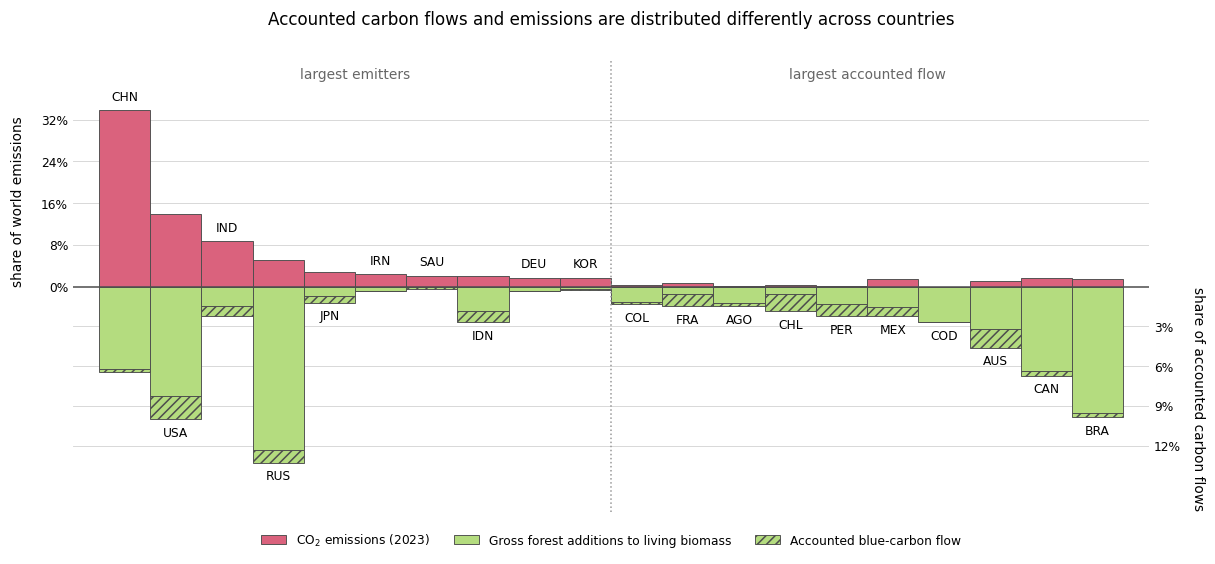

les 10 premiers émetteurs = 74 % des émissions mondiales
les 10 plus grands flux comptabilisés = 35 % des flux carbone comptabilisés


In [16]:
TOP_N = 10                  # pays retenus de chaque côté
WIDTH_METRIC = "equal"      # "equal", "population" ou "gdp" - voir la note sous la figure

bcw_tco2 = pd.Series((D_BCW / GSCC).mean(axis=1), index=UNITS, name="seq_bcw")

panel_src = (base[["iso3", "name", "groups", "co2_emissions_tco2_2023", "population", "gdp"]]
             .merge(gcw[["iso3", "uptake_tco2_yr_mean"]], on="iso3", how="left")
             .merge(bcw_tco2, left_on="iso3", right_index=True, how="left")
             .rename(columns={"uptake_tco2_yr_mean": "seq_gcw"})
             .dropna(subset=["co2_emissions_tco2_2023", "population", "seq_gcw", "seq_bcw"]))
panel_src["seq_total"] = panel_src["seq_gcw"] + panel_src["seq_bcw"]

# moitié gauche : plus gros émetteurs, décroissant ; moitié droite : plus grands flux comptabilisés, croissant
left = panel_src.nlargest(TOP_N, "co2_emissions_tco2_2023").sort_values(
    "co2_emissions_tco2_2023", ascending=False)
right = (panel_src[~panel_src["iso3"].isin(left["iso3"])]
         .nlargest(TOP_N, "seq_total").sort_values("seq_total"))
panel = pd.concat([left, right], ignore_index=True)
print(f"gauche : {', '.join(left['iso3'])}")
print(f"droite : {', '.join(right['iso3'])}")


EMIS_COLOR, SEQ_COLOR = "#da627d", "#b4dc7f"
EDGE = "#4d4d4d"

WORLD_EMIS = panel_src["co2_emissions_tco2_2023"].sum()
WORLD_SEQ = panel_src["seq_total"].sum()


def bar_updown(df, mode="share", stretch=True, width_metric=WIDTH_METRIC,
               fname="R2_bars_updown.png"):
    """Barres montantes = émissions ; barres descendantes = flux carbone comptabilisés.

    mode="share"    : chaque barre est une part du total mondial correspondant (%).
    mode="absolute" : totaux nationaux en MtCO2/an.
    stretch=True    : la moitié basse a sa propre échelle, pour que le plus grand flux comptabilisé
                      atteigne la même profondeur que la plus grande émission. Les graduations du
                      haut se lisent à gauche, celles du bas à droite.
    width_metric    : "equal" ; "population"/"gdp" pour un diagramme de Marimekko ;
                      "erosion" pour une largeur proportionnelle à l'intensité d'érosion (R3).
    """
    df = df.copy()
    if width_metric == "equal":
        widths, denom = np.ones(len(df)), np.ones(len(df))
    elif width_metric == "erosion":
        # largeur = intensité d'érosion (part du GCW national détruite chaque année).
        # Les pays sans déclaration de déforestation sortent du panneau : une largeur minimale
        # les ferait passer pour peu érodés .
        rate = df["iso3"].map(erosion_rate)
        dropped = df.loc[rate.isna(), "iso3"].tolist()
        if dropped:
            print("exclus, érosion non déclarée :", ", ".join(dropped))
        df = df[rate.notna()].copy()
        rate = rate.dropna().to_numpy()
        widths = 0.35 + 0.65 * (rate - rate.min()) / (rate.max() - rate.min())
        denom = np.ones(len(df))
    else:
        col = "population" if width_metric == "population" else "gdp"
        widths = df[col].to_numpy(dtype="float64")
        denom = widths
    widths = widths / widths.sum() * len(df)
    centres = np.cumsum(widths) - widths / 2

    emis = df["co2_emissions_tco2_2023"].to_numpy() / denom
    gcw_h = df["seq_gcw"].to_numpy() / denom
    bcw_h = df["seq_bcw"].to_numpy() / denom
    if mode == "share":
        emis, gcw_h, bcw_h = (100 * v / w for v, w in
                              ((emis, WORLD_EMIS), (gcw_h, WORLD_SEQ), (bcw_h, WORLD_SEQ)))
        unit, fmt = "%", "{:.0f}%"
    else:
        emis, gcw_h, bcw_h = (v / 1e6 for v in (emis, gcw_h, bcw_h))
        unit, fmt = "MtCO$_2$", "{:,.0f}"
    seq_h = gcw_h + bcw_h
    k = emis.max() / seq_h.max() if stretch else 1.0

    fig, ax = plt.subplots(figsize=(11, 5.2))
    bar = dict(width=widths, edgecolor=EDGE, linewidth=0.6)   # barres jointives
    ax.bar(centres, emis, color=EMIS_COLOR, label="CO$_2$ emissions (2023)", **bar)
    ax.bar(centres, -gcw_h * k, color=SEQ_COLOR, label="Gross forest additions to living biomass", **bar)
    ax.bar(centres, -bcw_h * k, bottom=-gcw_h * k, color=SEQ_COLOR, hatch="////",
           label="Accounted blue-carbon flow", **bar)
    span = max(emis.max(), (seq_h * k).max())
    ax.set_ylim(-span * 1.28, span * 1.28)
    ax.axhline(0, color=EDGE, lw=1.0)

    # étiquettes pays, horizontales, au bout de la barre dominante
    for c, e_, s_ in zip(centres, emis, seq_h * k):
        if e_ >= s_:
            ax.text(c, e_ + span * 0.04, "", ha="center")
    for c, iso, e_, s_ in zip(centres, df["iso3"], emis, seq_h * k):
        if e_ >= s_:
            ax.text(c, e_ + span * 0.04, iso, ha="center", va="bottom", fontsize=8)
        else:
            ax.text(c, -s_ - span * 0.04, iso, ha="center", va="top", fontsize=8)

    # graduations : émissions à gauche, flux comptabilisés à droite, avec leur propre échelle
    step = max(round(span / 4, 0), 1)
    up_ticks = np.arange(0, span + step / 2, step)
    ax.set_yticks(up_ticks)
    ax.set_yticklabels([fmt.format(v) for v in up_ticks], fontsize=8)
    ax2 = ax.twinx()
    ax2.set_ylim(ax.get_ylim())
    down_step = max(round(span / k / 4, 0), 1)
    down_ticks = np.arange(down_step, span / k + down_step / 2, down_step)
    ax2.set_yticks(-down_ticks * k)
    ax2.set_yticklabels([fmt.format(v) for v in down_ticks], fontsize=8)

    for a in (ax, ax2):
        for side in ("top", "right", "left", "bottom"):
            a.spines[side].set_visible(False)
        a.tick_params(length=0)
        a.grid(False)
    # grille horizontale des deux côtés de zéro, aux graduations réellement affichées
    for y in np.concatenate([up_ticks[1:], -down_ticks * k]):
        ax.axhline(y, color="#cccccc", lw=0.6, alpha=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.set_xticks([])
    ax.set_xlim(-0.5, widths.sum() + 0.5)
    
    split = widths[:TOP_N].sum()
    ax.axvline(split, color="#999999", ls=":", lw=1.0)
    ax.text(split / 2, span * 1.18, "largest emitters", ha="center", fontsize=9, color="#666666")
    ax.text(split + (widths.sum() - split) / 2, span * 1.18, "largest accounted flow",
            ha="center", fontsize=9, color="#666666")
    ax.set_ylabel("share of world emissions" if mode == "share" else f"emissions ({unit}/yr)",
                  fontsize=9, ha="left")
    ax2.set_ylabel("share of accounted carbon flows" if mode == "share" else f"accounted carbon flow ({unit}/yr)",
                   fontsize=9, rotation=270, ha="left")
    # les deux intitulés partent de la ligne zéro : celui de gauche monte, celui de droite descend
    zero_frac = (0 - ax.get_ylim()[0]) / (ax.get_ylim()[1] - ax.get_ylim()[0])
    ax.yaxis.set_label_coords(-0.045, zero_frac)
    ax2.yaxis.set_label_coords(1.052, zero_frac)
    ax.set_title("Accounted carbon flows and emissions are distributed differently across countries",
                 fontsize=11, pad=24)
    ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.02), frameon=False)
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=160); plt.show()


bar_updown(panel)
print(f"les {TOP_N} premiers émetteurs = {100 * left['co2_emissions_tco2_2023'].sum() / WORLD_EMIS:.0f} %"
      " des émissions mondiales")
print(f"les {TOP_N} plus grands flux comptabilisés = {100 * right['seq_total'].sum() / WORLD_SEQ:.0f} %"
      " des flux carbone comptabilisés")

## R3 - L'érosion du service 

La déforestation est comptée séparément comme une **perte de capacité annuelle d’ajout brut à la biomasse vivante**. Pour les surfaces converties, on estime la capacité annuelle associée avec les mêmes taux moyens Gibbs/GFW par biome et la même répartition en biomes ; on ne la décrit pas comme une émission directe de carbone ni comme une perte permanente garantie.

### R3.1 Surfaces déboisées (FRA 2025)

In [17]:
with zipfile.ZipFile(DATA / "raw" / "fra" / "fra2025_bulk_WO.zip") as z:
    name = [n for n in z.namelist() if "1d_deforestation" in n][0]
    defor = pd.read_csv(z.open(name))

INTERVALS = ["1990-2000", "2000-2010", "2010-2015", "2015-2020", "2020-2025"]
defor = defor.dropna(subset=["iso3"]).copy()
for c in INTERVALS:
    defor[c] = pd.to_numeric(defor[c], errors="coerce")

# période écologique du GCW  : moyenne des deux intervalles couvrant 2010-2019
defor["defor_kha_yr"] = defor[["2010-2015", "2015-2020"]].mean(axis=1)
defor = defor[["iso3", "name", "defor_kha_yr"] + INTERVALS]
print(f"monde 2010-2019 : {defor['defor_kha_yr'].sum() / 1000:.2f} Mha déboisés par an")
display(defor.nlargest(10, "defor_kha_yr")[["name", "defor_kha_yr"]].round(1))

# Couverture : tous les pays ne déclarent pas la déforestation à FRA
cov = gcw[["iso3", "gcw_usd2015_yr_mean"]].merge(defor[["iso3", "defor_kha_yr"]], on="iso3", how="left")
has = cov["defor_kha_yr"].notna()
print(f"unités FRA avec déforestation déclarée : {int(has.sum())} / {len(cov)}")
print(f"part du GCW mondial couverte : {100 * cov.loc[has, 'gcw_usd2015_yr_mean'].sum() / cov['gcw_usd2015_yr_mean'].sum():.1f} %")
print("plus gros GCW sans déclaration :",
      ", ".join(cov[~has].nlargest(8, "gcw_usd2015_yr_mean")["iso3"]))

monde 2010-2019 : 9.70 Mha déboisés par an


,name,defor_kha_yr
29,Brazil,2272.1
97,India,665.1
56,Democratic Republic of the Congo,645.2
98,Indonesia,541.1
5,Angola,510.4
12,Australia,444.7
223,United Republic of Tanzania,436.0
43,China,331.9
163,Paraguay,307.6
201,Sudan,268.3


unités FRA avec déforestation déclarée : 139 / 236
part du GCW mondial couverte : 78.7 %
plus gros GCW sans déclaration : USA, PER, BOL, ZMB, JPN, ZAF, MMR, FRA


### R3.2 Capacité détruite et sa valeur

Les hectares déboisés sont répartis entre biomes selon les parts forestières du pays. C’est une hypothèse d’allocation : les données ne localisent pas ici chaque hectare déboisé dans son biome.

Les taux de biome sont les moyennes fixes Gibbs/GFW. Leur écart-type spatial est une mesure d’hétérogénéité entre pixels et n’est pas tiré comme s’il s’agissait d’une incertitude sur la moyenne. Les montants monétaires varient avec les tirages du GSCC ; le flux physique de capacité perdue reste fixe.

In [18]:
shares = (area_biome.query("variant == 'documented_overlap_removed'")
          .pivot_table(index="iso3", columns="biome", values="area_ha", aggfunc="sum").fillna(0.0))
shares = shares.div(shares.sum(axis=1).replace(0, np.nan), axis=0).fillna(0.0)

biomes = list(shares.columns)
rate_means = np.array([rates.loc[b, "rate_tc_ha_yr_mean"] for b in biomes])
rate_draws = np.repeat(rate_means[:, None], N_DRAWS, axis=1)  # taux fixes : aucune incertitude de taux disponible

defor_ha = (defor.set_index("iso3")["defor_kha_yr"] * 1000).reindex(shares.index)
reported = defor_ha.notna().to_numpy()                    # unités déclarant leur déforestation
REPORTED_UNITS = np.isin(UNITS, shares.index[reported])   # même masque, aligné sur UNITS
area_by_biome = shares.mul(defor_ha.fillna(0.0), axis=0).to_numpy()   # (n_pays, n_biomes) ha/an
loss_tco2 = (area_by_biome @ rate_draws) * CARBON_TO_CO2  # (n_pays, 20000)
loss_usd = loss_tco2 * GSCC

loss = (summarise_rows(loss_usd, shares.index, prefix="loss_usd_")
        .join(summarise_rows(loss_tco2, shares.index, prefix="loss_tco2_")[["loss_tco2_mean"]]))
loss.index.name = "iso3"
# Les unités sans déclaration deviennent NaN : un zéro les lirait comme « pas de déforestation »,
# ce qui est faux pour le Pérou, la Bolivie ou le Myanmar. Les totaux ne portent donc que sur
# les pays déclarants, et le texte doit annoncer cette couverture.
loss.loc[~reported, :] = np.nan
print("monde, capacité détruite chaque année :",
      f"{np.nansum(loss_tco2, axis=0).mean() / 1e6:.1f} MtCO2/an |",
      usd(np.nansum(loss_usd, axis=0).mean(), "B"), "de GCW par an")
print(f"(total sur les {int(reported.sum())} unités déclarantes ; les autres sont absentes, pas nulles)")

monde, capacité détruite chaque année : 34.8 MtCO2/an | 19.49 B$ de GCW par an
(total sur les 139 unités déclarantes ; les autres sont absentes, pas nulles)


### R3.3 Part érodée, par pays et par groupe

In [19]:
r3 = base[["iso3", "name", "groups", "gdp", "gcw_usd2015_yr_mean"]].merge(
    loss.reset_index(), on="iso3", how="left")
r3["erosion_%_du_gcw"] = 100 * r3["loss_usd_mean"] / r3["gcw_usd2015_yr_mean"]
r3["loss_share_of_gdp"] = 100 * r3["loss_usd_mean"] / r3["gdp"]

covered = r3["loss_usd_mean"].notna()
print("érosion, pays déclarants seulement :",
      f"{100 * r3.loc[covered, 'loss_usd_mean'].sum() / r3.loc[covered, 'gcw_usd2015_yr_mean'].sum():.2f} %"
      " du GCW de ces pays, par an")
print(f"couverture : {int(covered.sum())} unités, soit "
      f"{100 * r3.loc[covered, 'gcw_usd2015_yr_mean'].sum() / r3['gcw_usd2015_yr_mean'].sum():.0f} % du GCW mondial")
display(r3.nlargest(12, "loss_usd_mean")[["name", "groups", "loss_usd_mean", "erosion_%_du_gcw",
                                          "loss_share_of_gdp"]]
        .assign(loss_usd_mean=lambda d: d["loss_usd_mean"].map(lambda v: usd(v, "B"))).round(2))
g = r3.groupby("groups")[["loss_usd_mean"]].sum()
display(g.assign(part_du_monde_pct=100 * g["loss_usd_mean"] / g["loss_usd_mean"].sum()).round(1))

érosion, pays déclarants seulement : 0.30 % du GCW de ces pays, par an
couverture : 139 unités, soit 79 % du GCW mondial


,name,groups,loss_usd_mean,erosion_%_du_gcw,loss_share_of_gdp
2,Brazil,Developing economies,4.41 B$,0.47,0.23
10,India,Developing economies,1.34 B$,0.91,0.04
7,Democratic Republic of the Congo,LDCs,1.24 B$,0.46,2.18
5,Australia,Developed economies,1.05 B$,0.33,0.06
6,Indonesia,Developing economies,1.04 B$,0.56,0.09
12,Angola,LDCs,0.98 B$,0.81,1.14
4,"China (incl. Taiwan, Hong Kong SAR and Macao SAR)",Developing economies,0.90 B$,0.15,0.01
22,United Republic of Tanzania,LDCs,0.84 B$,1.00,1.18
65,Paraguay,Developing economies,0.59 B$,2.15,1.34
37,Sudan,LDCs,0.51 B$,1.22,1.22


,loss_usd_mean,part_du_monde_pct
groups,,
Developed economies,1.592310e+09,8.2
Developing economies,1.140836e+10,58.5
LDCs,6.313734e+09,32.4
SIDS,1.727752e+08,0.9


### R3.4 Effet cumulé

Le cumul sur dix ans suppose que le rythme annuel estimé se maintient.
La valeur actualisée en perpétuité est un scénario conditionnel où le flux de capacité non fourni se poursuit indéfiniment.

In [20]:
DISCOUNT = 0.02   # TODO : taux d'actualisation à trancher ; sert uniquement à capitaliser une série (01 §1.3)

annual = np.nansum(loss_usd, axis=0)
print("valeur de la capacité annuelle d’ajout brut non fournie :", usd(annual.mean(), "B"),
      f"[{usd(np.percentile(annual, 5), 'B')} - {usd(np.percentile(annual, 95), 'B')}]")
print("cumul illustratif sur 10 ans si le rythme estimé se maintient :", usd(10 * annual.mean(), "B"))
print(f"valeur actualisée du scénario perpétuel conditionnel (r = {DISCOUNT:.0%}) :",
      usd(annual.mean() / DISCOUNT))
print("part du GCW des pays déclarants représentée par le cumul illustratif sur 10 ans :",
      f"{100 * 10 * annual.mean() / np.nansum(D_GCW[REPORTED_UNITS], axis=0).mean():.1f} %"
      " (rapportée au GCW des pays déclarants)")

valeur de la capacité annuelle d’ajout brut non fournie : 19.49 B$ [7.61 B$ - 35.38 B$]
cumul illustratif sur 10 ans si le rythme estimé se maintient : 194.87 B$
valeur actualisée du scénario perpétuel conditionnel (r = 2%) : 0.97 T$
part du GCW des pays déclarants représentée par le cumul illustratif sur 10 ans : 3.0 % (rapportée au GCW des pays déclarants)


### R3.5 Typologie : ampleur du service contre intensité de l'érosion

,nombre de pays
typologie,
grand service / érosion faible,33
petit service / érosion forte,33
grand service / érosion forte,20
petit service / érosion faible,19


Spearman service ~ intensité d'érosion : rho = -0.22 (p = 2.6e-02)


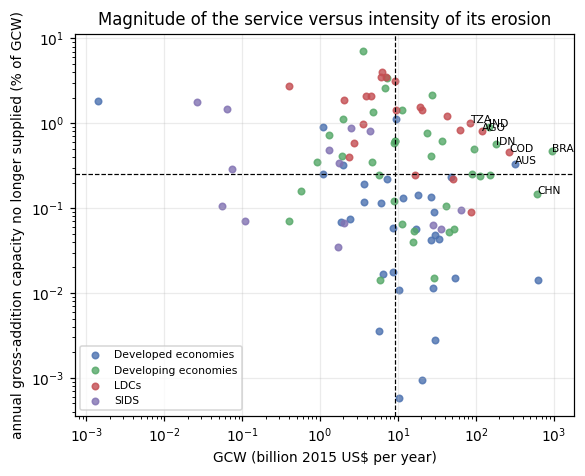

In [21]:
t = r3.dropna(subset=["gcw_usd2015_yr_mean", "erosion_%_du_gcw"]).query(
    "gcw_usd2015_yr_mean > 0 and `erosion_%_du_gcw` > 0")
med_gcw, med_ero = t["gcw_usd2015_yr_mean"].median(), t["erosion_%_du_gcw"].median()
t = t.assign(ampleur=np.where(t["gcw_usd2015_yr_mean"] >= med_gcw, "grand service", "petit service"),
             intensite=np.where(t["erosion_%_du_gcw"] >= med_ero, "érosion forte", "érosion faible"))
t["typologie"] = t["ampleur"] + " / " + t["intensite"]
display(t["typologie"].value_counts().to_frame("nombre de pays"))
rho, p = stats.spearmanr(t["gcw_usd2015_yr_mean"], t["erosion_%_du_gcw"])
print(f"Spearman service ~ intensité d'érosion : rho = {rho:.2f} (p = {p:.1e})")

fig, ax = plt.subplots(figsize=(5.4, 4.4))
for g_, d in t.groupby("groups"):
    ax.scatter(d["gcw_usd2015_yr_mean"] / 1e9, d["erosion_%_du_gcw"], s=18, alpha=0.8,
               color=GROUP_COLORS.get(g_, "grey"), label=g_)
for _, row in t.nlargest(8, "loss_usd_mean").iterrows():
    ax.annotate(row["iso3"], (row["gcw_usd2015_yr_mean"] / 1e9, row["erosion_%_du_gcw"]), fontsize=7)
ax.axvline(med_gcw / 1e9, color="k", ls="--", lw=0.8); ax.axhline(med_ero, color="k", ls="--", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("GCW (billion 2015 US$ per year)"); ax.set_ylabel("annual gross-addition capacity no longer supplied (% of GCW)")
ax.set_title("Magnitude of the service versus intensity of its erosion"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "R3_typologie.png"); plt.show()

### R3.6 Tendance de la déforestation

Pente de Theil-Sen et test de Mann-Kendall sur les intervalles FRA.
**Cinq points seulement** : la puissance est faible, le résultat reste indicatif.

In [22]:
mid = {"1990-2000": 1995, "2000-2010": 2005, "2010-2015": 2012.5, "2015-2020": 2017.5, "2020-2025": 2022.5}
years = np.array(list(mid.values()), dtype="float64")


def mann_kendall(y):
    y = np.asarray(y, dtype="float64")
    n = y.size
    s = sum(np.sign(y[j] - y[i]) for i in range(n - 1) for j in range(i + 1, n))
    var = n * (n - 1) * (2 * n + 5) / 18
    z = (s - np.sign(s)) / np.sqrt(var) if s != 0 else 0.0
    return s, 2 * (1 - stats.norm.cdf(abs(z)))


world_series = defor[INTERVALS].sum()
slope, _, lo, hi = stats.theilslopes(world_series.to_numpy(), years)
s, p = mann_kendall(world_series.to_numpy())
print(world_series.round(0).to_string())
print(f"\nmonde : Theil-Sen = {slope:.1f} kha/an par an [{lo:.1f}, {hi:.1f}] ; Mann-Kendall S = {s}, p = {p:.2f}")

rows = []
for _, r in defor.nlargest(10, "defor_kha_yr").iterrows():
    y = r[INTERVALS].to_numpy(dtype="float64")
    if np.isnan(y).any():
        continue
    rows.append({"pays": r["name"], "pente (kha/an par an)": stats.theilslopes(y, years)[0],
                 "S": mann_kendall(y)[0], "p": mann_kendall(y)[1]})
display(pd.DataFrame(rows).round(3))

1990-2000    15819.0
2000-2010    13329.0
2010-2015     9878.0
2015-2020     9478.0
2020-2025     8484.0

monde : Theil-Sen = -271.8 kha/an par an [-460.1, -80.1] ; Mann-Kendall S = -10.0, p = 0.03


,pays,pente (kha/an par an),S,p
0,Brazil,-128.306,-4.0,0.462
1,India,3.885,2.0,0.806
2,Democratic Republic of the Congo,-15.825,-4.0,0.462
3,Indonesia,-59.094,-10.0,0.027
4,United Republic of Tanzania,2.667,6.0,0.221
5,China,-0.670,0.0,1.000
6,Paraguay,-7.253,-9.0,0.050
7,Sudan,-0.345,-6.0,0.221


### R3.7 La figure en barres, largeur proportionnelle à l'érosion

Variante de la figure de R2 : la largeur de chaque barre est la part du GCW associée à la capacité annuelle
d'ajout brut à la biomasse vivante qui n'est plus fournie par les surfaces converties. Les pays qui ne déclarent pas leur déforestation sortent du panneau,
car une largeur minimale les ferait passer pour peu érodés .

exclus, érosion non déclarée : USA, JPN, FRA, PER


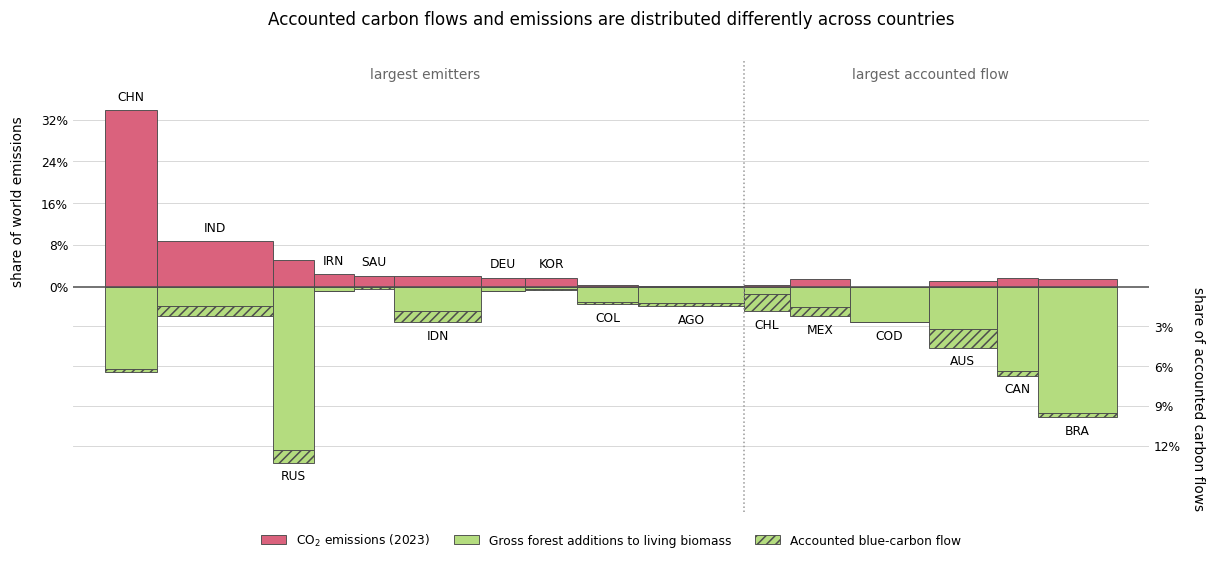

In [23]:
erosion_rate = r3.set_index("iso3")["erosion_%_du_gcw"]
bar_updown(panel, width_metric="erosion", fname="R3_bars_updown_erosion.png")

## R4 - Le coût de la compensation 

Un puits perdu doit être remplacé par de l'abattement si l'objectif climatique est maintenu.
La tonne perdue reçoit alors **deux prix** :

- le **GSCC** (559,6 US$2015/tCO₂) : le dommage évité, donc la valeur de bien-être perdue ;
- un **prix carbone de scénario AR6** : ce qu'il en coûte de la remplacer.

In [24]:
# TODO : remplacer par les prix de la base de scénarios AR6 du GIEC
# (préciser scénario, année et conversion en dollars constants de 2015).
AR6_PRICES = {"placeholder_bas": 50.0, "placeholder_central": 150.0, "placeholder_haut": 400.0}

lost_tco2 = np.nansum(loss_tco2, axis=0).mean()
value_lost = np.nansum(loss_usd, axis=0).mean()
rows = [{"scénario": k, "prix (US$/tCO2)": v,
         "coût annuel de compensation": usd(lost_tco2 * v, "B"),
         "coût / valeur perdue": lost_tco2 * v / value_lost} for k, v in AR6_PRICES.items()]
display(pd.DataFrame(rows).round(3))
print("capacité perdue chaque année :", f"{lost_tco2 / 1e6:.1f} MtCO2/an")
print("valeur de bien-être perdue (GSCC) :", usd(value_lost, "B"))

,scénario,prix (US$/tCO2),coût annuel de compensation,coût / valeur perdue
0,placeholder_bas,50.0,1.74 B$,0.089
1,placeholder_central,150.0,5.22 B$,0.268
2,placeholder_haut,400.0,13.93 B$,0.715


capacité perdue chaque année : 34.8 MtCO2/an
valeur de bien-être perdue (GSCC) : 19.49 B$


### R4.1 Scénario de remplacement

Le coût de remplacement d’une année de capacité annuelle non fournie dépend de la durée pendant laquelle
la surface reste convertie et de l’absence de restauration. Le calcul perpétuel ci-dessous est un scénario
conditionnel, pas une durée observée ni une conséquence automatique d’une année de déforestation.

In [25]:
PRICE = AR6_PRICES["placeholder_central"]
annual_cost = lost_tco2 * PRICE
print("coût annuel illustratif de remplacement de la capacité estimée :", usd(annual_cost, "B"))
print(f"valeur actualisée si le coût annuel se poursuit indéfiniment, à {DISCOUNT:.0%} :", usd(annual_cost / DISCOUNT))
print("après 10 ans au même rythme, effort annuel supplémentaire :",
      f"{10 * lost_tco2 / 1e6:.0f} MtCO2/an, soit", usd(10 * annual_cost, "B"), "par an")

coût annuel illustratif de remplacement de la capacité estimée : 5.22 B$
valeur actualisée si le coût annuel se poursuit indéfiniment, à 2% : 0.26 T$
après 10 ans au même rythme, effort annuel supplémentaire : 348 MtCO2/an, soit 52.24 B$ par an


### R4.2 Qui perd, qui paie

Sans courbes de coût marginal, on ne modélise pas un marché : on compare deux **règles d'allocation**.

1. **Sans échange** : chaque pays compense ses propres pertes.
2. **Effort mondial partagé** : le coût total est réparti au prorata du PIB.

`TODO` : brancher de vraies courbes de coût marginal (Favero & Austin, ou DART) pour un régime de marché,
où les tonnes les moins chères sont abattues d'abord.

,cost_national,cost_shared,écart (Md$)
groups,,,
Developed economies,0.43 B$,2.16 B$,-1.7
Developing economies,3.00 B$,2.86 B$,0.1
LDCs,1.69 B$,0.08 B$,1.6
SIDS,0.05 B$,0.06 B$,-0.0


Gini des pertes : 0.841 | Gini de la charge partagée : 0.827


,name,groups,cost_national,cost_national_share_of_gdp
23,Central African Republic,LDCs,0.02 B$,1.021
52,Somalia,LDCs,0.08 B$,0.854
27,Mozambique,LDCs,0.14 B$,0.671
120,Chad,LDCs,0.07 B$,0.601
7,Democratic Republic of the Congo,LDCs,0.33 B$,0.583
62,Madagascar,LDCs,0.08 B$,0.569
78,Mali,LDCs,0.08 B$,0.440
127,Burkina Faso,LDCs,0.07 B$,0.386
65,Paraguay,Developing economies,0.16 B$,0.359
37,Sudan,LDCs,0.14 B$,0.326


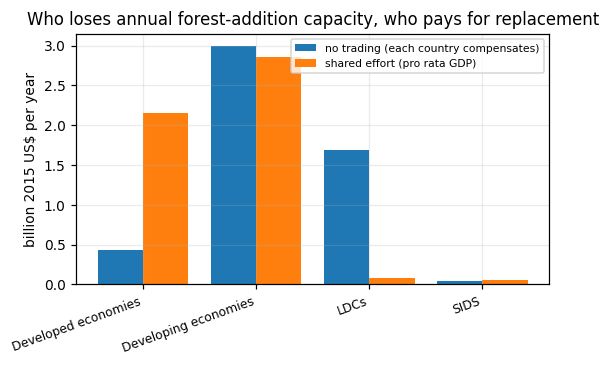

In [26]:
alloc = r3.dropna(subset=["loss_tco2_mean", "gdp"]).copy()
alloc["cost_national"] = alloc["loss_tco2_mean"] * PRICE
alloc["cost_shared"] = alloc["cost_national"].sum() * alloc["gdp"] / alloc["gdp"].sum()
alloc["cost_national_share_of_gdp"] = 100 * alloc["cost_national"] / alloc["gdp"]

by_grp = alloc.groupby("groups")[["cost_national", "cost_shared"]].sum().reindex(GROUP_ORDER)
by_grp["écart (Md$)"] = (by_grp["cost_national"] - by_grp["cost_shared"]) / 1e9
display(by_grp.assign(**{c: by_grp[c].map(lambda v: usd(v, "B")) for c in ["cost_national", "cost_shared"]}).round(1))
print(f"Gini des pertes : {gini(alloc['loss_tco2_mean']):.3f} |",
      f"Gini de la charge partagée : {gini(alloc['cost_shared']):.3f}")
display(alloc.nlargest(10, "cost_national_share_of_gdp")[
    ["name", "groups", "cost_national", "cost_national_share_of_gdp"]]
    .assign(cost_national=lambda d: d["cost_national"].map(lambda v: usd(v, "B"))).round(3))

fig, ax = plt.subplots(figsize=(5.2, 3.4))
idx = np.arange(len(by_grp))
ax.bar(idx - 0.2, by_grp["cost_national"] / 1e9, 0.4, label="no trading (each country compensates)")
ax.bar(idx + 0.2, by_grp["cost_shared"] / 1e9, 0.4, label="shared effort (pro rata GDP)")
ax.set_xticks(idx); ax.set_xticklabels(by_grp.index, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("billion 2015 US$ per year"); ax.legend(fontsize=7)
ax.set_title("Who loses annual forest-addition capacity, who pays for replacement")
fig.tight_layout(); fig.savefig(FIG / "R4_qui_paie.png"); plt.show()

### R4.3 Scénarios d'affaiblissement du puits océanique

Le BCW n'a pas de pertes observées : on applique les scénarios de Rickels et al. (2024), −5 % et −10 %.

In [27]:
rows = []
for pct in (0.05, 0.10):
    ocean_tco2 = (np.nansum(D_BCW, axis=0) / GSCC).mean() * pct
    rows.append({"scénario": f"puits océanique −{pct:.0%}",
                 "tonnes perdues (MtCO2/an)": ocean_tco2 / 1e6,
                 "valeur perdue (GSCC)": usd(ocean_tco2 * GSCC.mean(), "B"),
                 "coût de compensation": usd(ocean_tco2 * PRICE, "B")})
rows.append({"scénario": "déforestation observée (une année)",
             "tonnes perdues (MtCO2/an)": lost_tco2 / 1e6,
             "valeur perdue (GSCC)": usd(value_lost, "B"),
             "coût de compensation": usd(annual_cost, "B")})
display(pd.DataFrame(rows).round(1))

,scénario,tonnes perdues (MtCO2/an),valeur perdue (GSCC),coût de compensation
0,puits océanique −5%,208.1,116.45 B$,31.22 B$
1,puits océanique −10%,416.2,232.91 B$,62.43 B$
2,déforestation observée (une année),34.8,19.49 B$,5.22 B$


## Annexes

Indicateurs par habitant, conservés pour la continuité avec BCW,
puis contrôle de sensibilité sur les mangroves.

In [28]:
ann = base.dropna(subset=["ncw_usd2015_yr_mean"]).copy()
ann["gcw_per_capita"] = ann["gcw_usd2015_yr_mean"] / ann["population"]
ann["ncw_per_capita"] = ann["ncw_usd2015_yr_mean"] / ann["population"]
ann = ann.merge(r3[["iso3", "loss_usd_mean"]], on="iso3", how="left")
ann["loss_per_capita"] = ann["loss_usd_mean"] / ann["population"]

print("NCW par habitant, moyenne pondérée par la population :",
      f"{ann['ncw_usd2015_yr_mean'].sum() / ann['population'].sum():,.0f} US$2015")
print(f"moyenne non pondérée entre pays : {ann['ncw_per_capita'].mean():,.0f} US$2015")
display(ann.nlargest(15, "ncw_per_capita")[["name", "groups", "gcw_per_capita", "ncw_per_capita"]].round(0))
display(ann.groupby("groups")[["gcw_per_capita", "ncw_per_capita", "loss_per_capita"]].median().round(1))
ann[["iso3", "name", "groups", "gcw_per_capita", "ncw_per_capita", "loss_per_capita"]].to_csv(
    OUT / "tables" / "annexe_per_capita.csv", index=False)

NCW par habitant, moyenne pondérée par la population : 1,308 US$2015
moyenne non pondérée entre pays : 19,865 US$2015


,name,groups,gcw_per_capita,ncw_per_capita
109,Cook Islands,SIDS,2102.0,688319.0
173,Niue,SIDS,19910.0,601401.0
136,Tuvalu,SIDS,201.0,490884.0
80,Marshall Islands,SIDS,479.0,473974.0
139,Naoero,SIDS,0.0,347838.0
133,Palau,SIDS,4528.0,316818.0
49,Seychelles,SIDS,397.0,273051.0
59,Micronesia (Federated States of),SIDS,1099.0,262771.0
31,Kiribati,SIDS,0.0,133876.0
43,Bahamas,SIDS,1766.0,97210.0


,gcw_per_capita,ncw_per_capita,loss_per_capita
groups,,,
Developed economies,749.4,1103.1,0.4
Developing economies,488.9,902.3,1.4
LDCs,504.4,806.5,9.3
SIDS,459.0,5001.9,1.2


In [29]:
# Sensibilité : mangroves retirées du BCW au lieu du GCW (alternative conservée)
sens = base.dropna(subset=["ncw_alt_mangroves_usd2015_yr_mean"])
delta = sens["ncw_alt_mangroves_usd2015_yr_mean"].sum() - sens["ncw_usd2015_yr_mean"].sum()
print("NCW mondial, variante mangroves :", usd(sens["ncw_alt_mangroves_usd2015_yr_mean"].sum()),
      "| écart :", usd(delta, "B"))

NCW mondial, variante mangroves : 10.52 T$ | écart : -54.76 B$


## Points restés ouverts

| Sujet | Où | Ce qu'il faut |
|---|---|---|
| Émissions de CO₂ de la table BCW | R2 | Savoir si elles incluent l'usage des terres (double compte avec R3) |
| Seuil de tension de dette | R2.3 | Reprendre la valeur de la Fig. 5c de BCW |
| Seuil vert / bleu / mixte | R2.1 | Valider 2/3 ou un autre seuil |
| Incertitude des taux Gibbs/GFW | R1, R3 | Aucune incertitude statistique par biome n’est publiée ; l’écart-type spatial reste une sensibilité descriptive |
| Répartition des hectares déboisés entre biomes | R3.2 | Hypothèse de parts forestières nationales ; la localisation par biome n’est pas observée ici |
| Prix AR6 | R4 | Récupérer les prix réels : scénario, année, dollars 2015  |
| Courbes de coût marginal | R4.2 | Favero & Austin ou DART, pour un vrai régime de marché |
| Taux d'actualisation | R3.4, R4.1 | Uniquement pour capitaliser une série, à trancher |